# 01 · EDA de estacionariedad: elegir d y D

Muestra de identificación 2012-01-23 → 2020-12-28 (anterior al primer origen del backtest, 2021-01-04). Referencia: muestra completa 2012–2025. Serie: `y = log1p(hotspots)`. La lógica está en `fires/eda.py`.

In [1]:
import pandas as pd

from fires import eda
from fires.backtest import RESULTS

pd.set_option('display.width', 160)
samples, n_nan = eda.identification_samples()
print('NaN antes de interpolar:', n_nan)
print({k: (v.index[0].date(), v.index[-1].date(), len(v)) for k, v in samples.items()})

NaN antes de interpolar: {'ident': 0, 'full': 6}
{'ident': (datetime.date(2012, 1, 23), datetime.date(2020, 12, 28), 467), 'full': (datetime.date(2012, 1, 23), datetime.date(2025, 12, 22), 727)}


La muestra de identificación **no tiene NaN** (no se interpoló nada). La muestra completa tiene 6 semanas NaN interiores (apagones 2022 y 2024), interpoladas linealmente en log1p solo para estas pruebas; se descartó además la semana parcial final (2025-12-29).

In [2]:
tab = eda.stationarity_table(samples)
tab.to_csv(RESULTS / 'stationarity.csv', index=False)
tab[tab['sample'] == 'ident'].round(4)

,sample,series,test,regression,stat,pvalue,lags,pvalue_truncated,conclusion
0,ident,y,ADF,c,-7.6350,0.0000,14,False,estacionaria
1,ident,y,ADF,ct,-8.2060,0.0000,16,False,estacionaria
2,ident,y,KPSS,c,0.4192,0.0689,12,False,estacionaria
3,ident,y,KPSS,ct,0.0231,0.1000,12,True,estacionaria
4,ident,Δ1 y,ADF,c,-6.1387,0.0000,18,False,estacionaria
5,ident,Δ1 y,KPSS,c,0.0226,0.1000,25,True,estacionaria
6,ident,Δ52 y,ADF,c,-6.3700,0.0000,3,False,estacionaria
7,ident,Δ52 y,KPSS,c,0.1680,0.1000,9,True,estacionaria
8,ident,Δ1Δ52 y,ADF,c,-10.3352,0.0000,8,False,estacionaria
9,ident,Δ1Δ52 y,KPSS,c,0.1216,0.1000,92,True,estacionaria


Lectura: ADF rechaza raíz unitaria en las cuatro series (p≈0). KPSS no rechaza estacionariedad en ninguna (p-valores `0.1` truncados salvo `y` con constante, p=0.069, límite a 5 %). Ambas pruebas coinciden: **y es estacionaria en nivel** (d = 0). Los resultados con la muestra completa (filas `full`) son iguales.

In [3]:
tr = eda.transforms(samples['ident'])
eda.acf_key_lags(tr).round(3)

,lag 1,lag 2,lag 52,lag 104,lag 156
y,0.835,0.777,0.675,0.575,0.495
Δ1 y,-0.332,-0.131,-0.007,0.031,0.032
Δ52 y,0.278,0.122,-0.435,-0.022,0.011
Δ1Δ52 y,-0.393,-0.187,-0.469,0.029,-0.019


Lectura: `y` conserva ACF 0.68 / 0.58 / 0.50 en los lags 52/104/156, un decaimiento lento (señal de estacionalidad persistente). Tras Δ52 el lag 52 pasa a −0.44, y tras Δ1Δ52 a −0.47: cerca de −0.5, la firma de **sobrediferenciación** (MA estacional con θ≈−1).

In [4]:
res = {k: eda.seasonal_diffs(v) for k, v in samples.items()}
res

{'ident': {'ocsb': 0, 'ch': 0}, 'full': {'ocsb': 0, 'ch': 0}}

`nsdiffs(m=52)` con OCSB y CH da **D = 0** en ambas muestras.

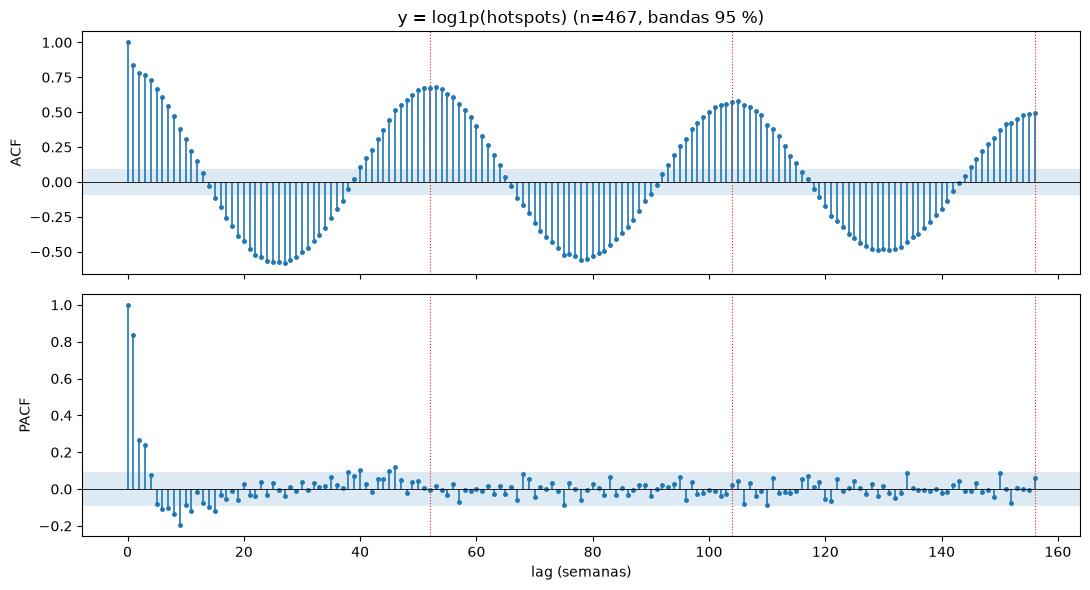

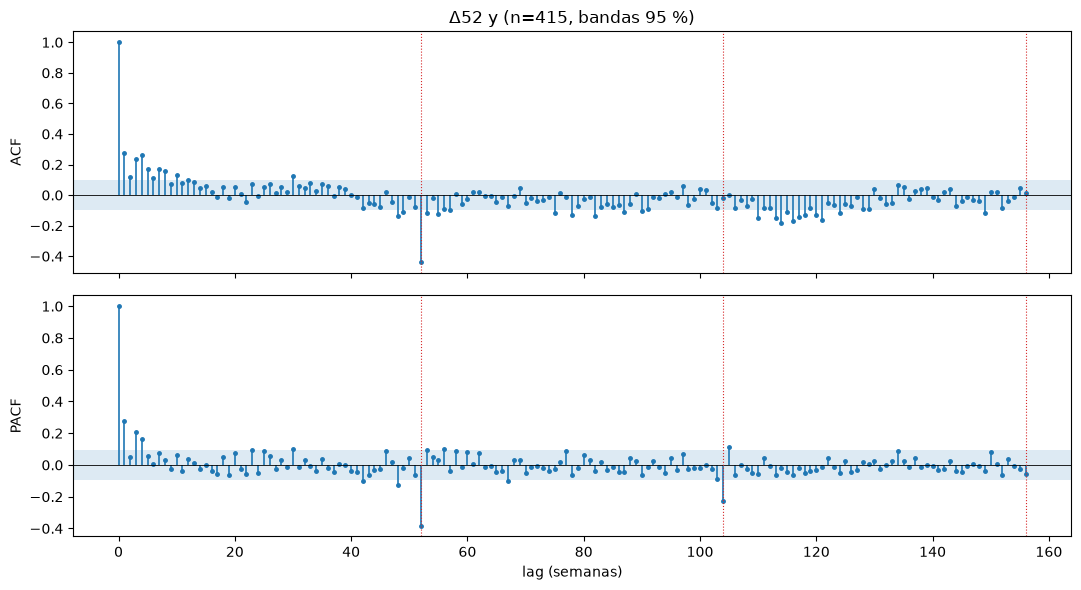

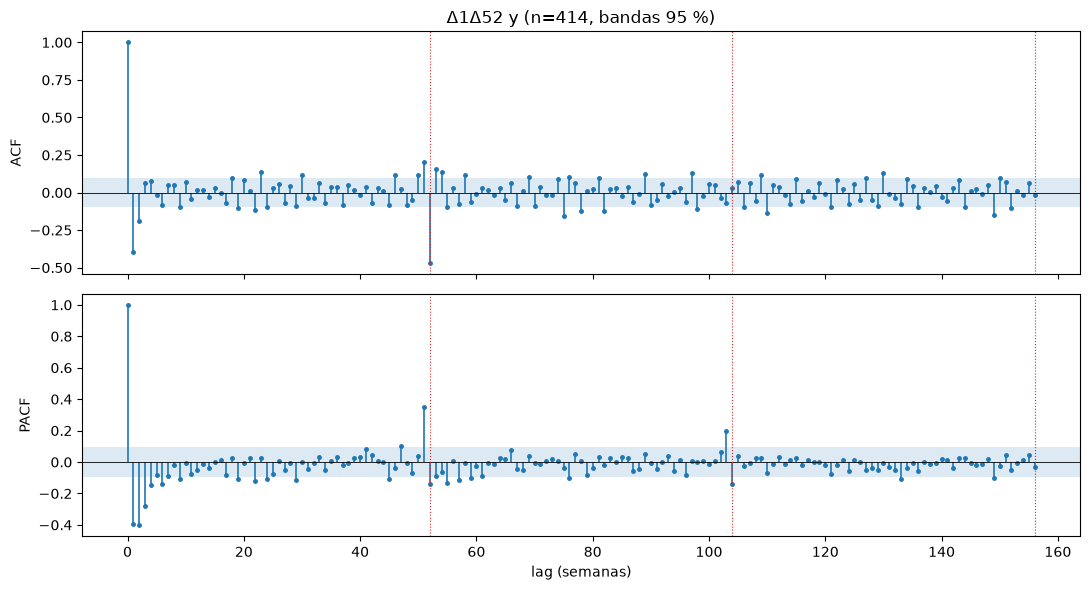

In [5]:
import matplotlib.pyplot as plt

slug = {'y': 'y', 'd52': 'd52', 'd1d52': 'd1d52'}
for k, name in [('y', 'y = log1p(hotspots)'), ('d52', 'Δ52 y'), ('d1d52', 'Δ1Δ52 y')]:
    eda.plot_acf_pacf(tr[k], name, RESULTS / 'figures' / f'acf_pacf_{slug[k]}.png')
    plt.show()

In [6]:
import numpy as np

for k in ('y', 'd52'):
    a, p = eda.acf_pacf(tr[k]); b = 1.96 / np.sqrt(len(tr[k]))
    print(k, 'banda', round(b, 3))
    print('  ACF  1-8 :', a[1:9].round(2)); print('  PACF 1-8 :', p[1:9].round(2))
    print('  PACF 52/104/156:', p[[52, 104, 156]].round(2))

y banda 0.091
  ACF  1-8 : [0.83 0.78 0.77 0.73 0.67 0.61 0.55 0.47]
  PACF 1-8 : [ 0.83  0.27  0.24  0.08 -0.08 -0.11 -0.1  -0.14]
  PACF 52/104/156: [-0.01  0.02  0.06]
d52 banda 0.096
  ACF  1-8 : [0.28 0.12 0.24 0.26 0.17 0.11 0.17 0.16]
  PACF 1-8 : [0.28 0.05 0.21 0.16 0.06 0.   0.07 0.03]
  PACF 52/104/156: [-0.38 -0.23 -0.06]


## Propuesta

**d = 0, D = 0.**

- **d = 0:** ADF rechaza y KPSS no rechaza, con constante y con tendencia, en ambas muestras. No hace falta Δ1; de hecho Δ1 introduce un MA(1) (ACF lag 1 = −0.33).
- **D = 0:** OCSB y CH dan 0. Δ52 deja ACF(52) = −0.44 con PACF decayendo (−0.38, −0.23 en 52, 104), el patrón de MA estacional con θ cercano a −1: sobrediferenciación. Además `y` ya es estacionaria, y la ACF alta en los lags estacionales (0.68, 0.58, 0.50) es compatible con un patrón anual **determinista** (pico muy regular) más que con una raíz unitaria estacional.
- **Consecuencia para la fase 3:** la evidencia favorece **Fourier-ARIMA con D = 0** (armónicos K = 2–4 como exógenas, errores ARMA). SARIMA con D = 0 y s = 52 queda como alternativa: sus términos estacionales P/Q tendrían que absorber la estacionalidad determinista, algo que Fourier hace de forma más directa.

**Órdenes candidatos (lectura preliminar sobre `y`, d = D = 0):**

- PACF: 0.83, 0.27, 0.24, luego |PACF| ≲ 0.1 hasta cerca del lag 8; corta tras el lag 3 → **p ∈ {2, 3}**. La ACF decae lentamente (0.83, 0.78, 0.77, 0.73…), coherente con AR de orden bajo más el componente estacional; **q ∈ {0, 1}**.
- Lag 52: PACF(52) ≈ −0.01, PACF(104) ≈ 0.02, sin pico, mientras la ACF permanece alta. Por tanto, **P ∈ {0, 1}, Q ∈ {0, 1}**, con poca justificación para términos estacionales fuertes; la estacionalidad pasa a Fourier (o a P = 1 como mínimo). Con n = 467 el SARIMA s = 52 estima mal los parámetros estacionales.
- Candidatos concretos para la grilla: ARMA(p,q) con p ∈ {1,2,3}, q ∈ {0,1} + Fourier K ∈ {2,3,4}; y SARIMA(p,0,q)(P,0,Q)₅₂ con P,Q ∈ {0,1} y constante.

*Advertencia:* ADF y KPSS tienen poca potencia con 9 años y fuerte estacionalidad; la ACF no decae a cero en 156 lags y una tendencia lenta (la serie sube desde 2019) puede quedar fuera de la muestra de identificación. Esto debe revisarse en los residuos de la fase 3.